# Run scanpy PAGA and calculate diffusion pseudotime : CTL data

In [1]:
import scanpy as sc
from anndata import read_h5ad
import pandas as pd

In [2]:
adata = sc.read("Pseudotime_input.h5ad")

In [3]:
adata

AnnData object with n_obs × n_vars = 15933 × 24641
    obs: 'cell_type', 'sample'
    obsm: 'X_umap'

In [4]:
adata.obs

,cell_type,sample
AAACGAATCAAGTGGG-1_1,LC_ER-_LuP,CTL
AAAGAACTCTAAACGC-1_1,Myo,CTL
AAAGGGCTCTGTCAGA-1_1,LC_ER-_LuP,CTL
AAAGTCCAGTGCTCGC-1_1,LC_ER+_Foxa1,CTL
AAAGTCCCACTGGACC-1_1,LC_ER-_LuP,CTL
...,...,...
TTTGTTGCATCGAAGG-1_3,LC_ER+_Sca1,ER_Pik
TTTGTTGGTTAGAGTA-1_3,Late_HY,ER_Pik
TTTGTTGTCCTTCTGG-1_3,Late_HY,ER_Pik
TTTGTTGTCGCAAGAG-1_3,LC_ER+_Foxa1,ER_Pik


In [5]:
# PCA
sc.pp.pca(adata, n_comps=50)

In [6]:
adata_sub = adata[adata.obs["sample"] == "CTL"].copy()

In [7]:
adata_sub.obs["cell_type"].unique()

['LC_ER-_LuP', 'Myo', 'LC_ER+_Foxa1', 'LC_ER-_LaP', 'LC_ER+_Sca1']
Categories (5, object): ['LC_ER+_Foxa1', 'LC_ER+_Sca1', 'LC_ER-_LaP', 'LC_ER-_LuP', 'Myo']

In [8]:
# Compute neighborhood graph
sc.pp.neighbors(adata_sub, n_neighbors=15, n_pcs=50)

In [9]:
sc.tl.paga(adata_sub, groups='cell_type')

In [10]:
# 1) Compute diffusion map (DPT depends on it)
sc.tl.diffmap(adata_sub)

In [11]:
# 2) Pick a root cell (string id) – e.g. any cell from your start cluster
root_group = "LC_ER+_Sca1"
root_cell = adata_sub.obs_names[adata_sub.obs["cell_type"] == root_group][0]

In [12]:
# 3) Set iroot (integer index of the root cell)
import numpy as np
adata_sub.uns['iroot'] = np.where(adata_sub.obs_names == root_cell)[0][0]

In [13]:
# 4) Run DPT
sc.tl.dpt(adata_sub, n_dcs=10)   # pseudotime in adata_sub.obs['dpt_pseudotime']

## Open-end

In [15]:
# Rescale DPT from the selected ER+ LC root to 0–1
pt = adata_sub.obs["dpt_pseudotime"].astype(float)
pt = pt.where(np.isfinite(pt))  # Keep cells with undefined DPT as NaN

pt_min, pt_max = pt.min(), pt.max()
if not pt_max > pt_min:
    raise ValueError("Rescaling requires at least two distinct finite DPT values.")

adata_sub.obs["dpt_rescaled"] = (pt - pt_min) / (pt_max - pt_min)

<Axes:>

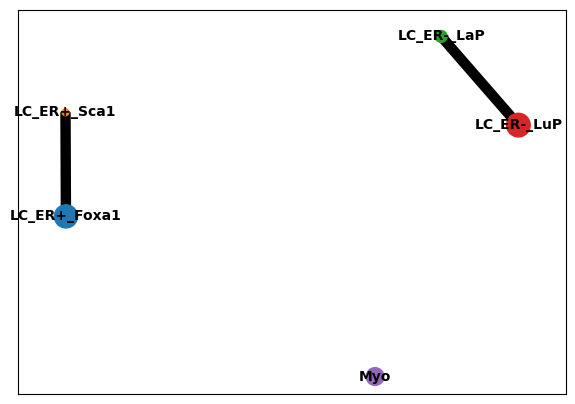

In [16]:
sc.pl.paga(adata_sub, color=['cell_type'], threshold=0.5, show=False)

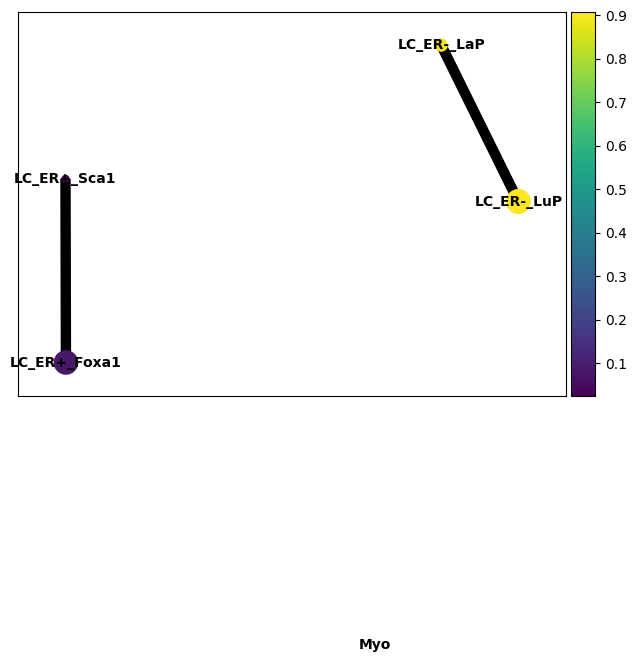

In [17]:
sc.pl.paga(adata_sub, color="dpt_rescaled", cmap="viridis", threshold=0.5)

## Constrained pseudotime

In [18]:
# Orient toward an end cluster: Based on lineage-trajectory / resclaing pseudotime
end_group = "Myo"
pt = adata_sub.obs["dpt_pseudotime"].astype(float).copy()

if pt[adata_sub.obs["cell_type"] == end_group].mean() < pt[adata_sub.obs["cell_type"] == root_group].mean():
    pt = 1.0 - pt

pt = (pt - np.nanmin(pt)) / (np.nanmax(pt) - np.nanmin(pt) + 1e-12)
adata_sub.obs["pt_oriented"] = pt

<Axes:>

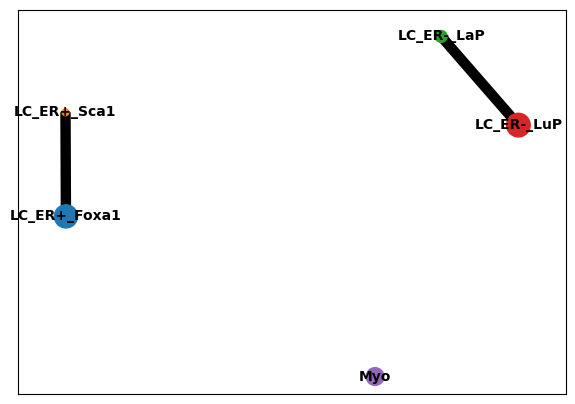

In [19]:
sc.pl.paga(adata_sub, color=['cell_type'], threshold=0.5, show=False)

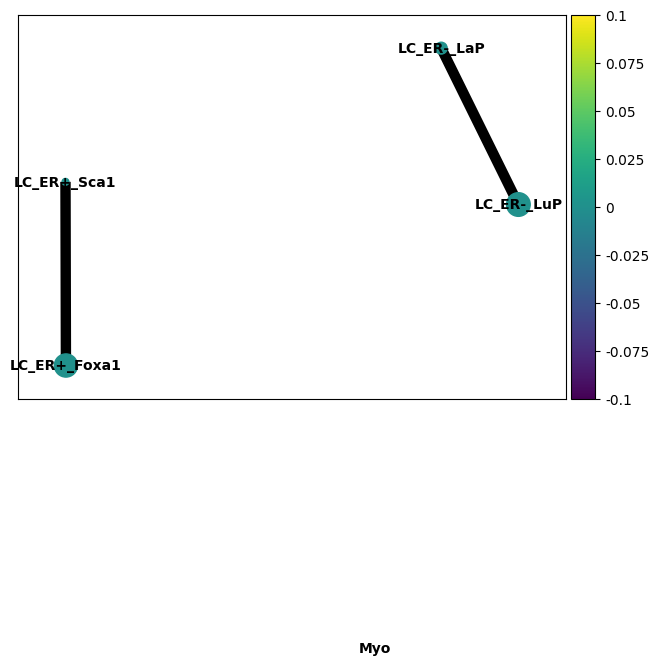

In [20]:
sc.pl.paga(adata_sub, color=["pt_oriented"], threshold=0.5, save="_CTL.pdf")